## Week 5 Lab exercises

In this week we will practise linear algebra using numpy and sympy, and look at the solution of linear ODEs with implicit methods.

In [1]:
# first we import the libraries we need
import numpy as np
import numpy.matlib
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# The following lines makes the plots appear inline in the notebook
%matplotlib inline

### ACTIVITY 1:

I have written a class below for integrating linear equations that implements the (explicit) forward Euler method using matrix methods. Update it to include the (implicit) backwards Euler method. Be sure to add in asserts to sense check what the class is doing.

The class is applied to the system we saw in the lectures:

$\dot x = 998 x + 1998y \quad x(0) = 1$

$\dot y = -999 x - 1999y \quad y(0) = 0$

which can also be written as

$\frac{d}{dt}\begin{bmatrix}
x \\
y
\end{bmatrix} = \begin{bmatrix}
998 & 1998\\
-999 & -1999
\end{bmatrix} \begin{bmatrix}
x \\
y
\end{bmatrix}$

Determine:

1. What is the maximum step size we can take while still keeping the Forward Euler method _stable_?
2. Is this consistent with the bounds we saw in the lecture?
3. What step size do we need to take in order to keep the Backward Euler method _stable_?
4. Is this consistent with the bounds we saw in the lecture?
5. What step size do we need to take in order to render the Backward Euler method _accurate_?

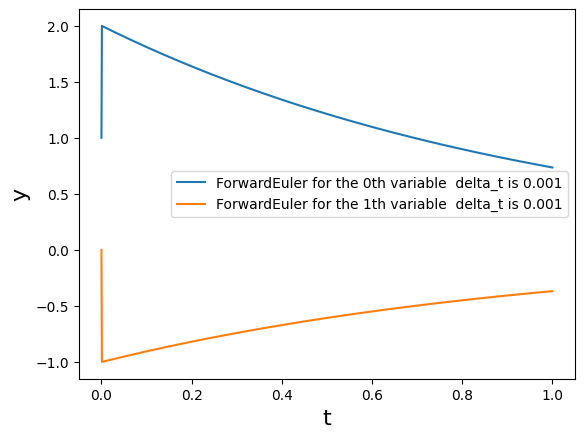

In [3]:
# ExplicitLinearIntegrator class

class ExplicitLinearIntegrator :

    """
    Contains explicit methods to integrate ODEs

    attributes: the function to calculate the gradient dydt, max_time,
                N_time_steps, method

    methods: calculate_solution, plot_solution

    """
    integration_methods = ["ForwardEuler", "BackwardEuler"]

    # constructor function
    def __init__(self, a_C_matrix, max_time=0, N_time_steps=0, method = "ForwardEuler"):

        self.C_matrix = a_C_matrix # Note that we are passing in a function, this is ok in python
        self.method = method
        assert self.method in self.integration_methods, 'chosen integration method not implemented'

        # Make these private - restrict getting and setting as below
        self._dimension = np.size(self.C_matrix, 0)
        self._max_time = max_time
        self._N_time_steps = N_time_steps

        # Derived from the values above
        self._delta_t = self.max_time / self.N_time_steps
        self._t_solution = np.linspace(0.0, self.max_time, self.N_time_steps+1)
        self._y_solution = np.zeros([self.N_time_steps+1, self._dimension])

    # Enables the user to get the y solution
    @property
    def y_solution(self):
        return self._y_solution

    # Enables the user to get the t solution
    @property
    def t_solution(self):
        return self._t_solution

    @property
    def max_time(self):
        return self._max_time

    @property
    def N_time_steps(self):
        return self._N_time_steps

    # Enables the user to reset the max time
    @max_time.setter
    def max_time(self, value):
        self._max_time = value
        self._delta_t = self.max_time / self.N_time_steps
        self._t_solution = np.linspace(0.0, self.max_time, self.N_time_steps+1)
        self._y_solution = np.zeros([self.N_time_steps+1,self._dimension])

    # Enables the user to reset the number of time steps
    @N_time_steps.setter
    def N_time_steps(self, value):
        self._N_time_steps = value
        self._delta_t = self.max_time / self.N_time_steps
        self._t_solution = np.linspace(0.0, self.max_time, self.N_time_steps+1)
        self._y_solution = np.zeros([self.N_time_steps+1,self._dimension])

    def calculate_solution(self, y0) :
        if (self.method == "ForwardEuler") :
            self.integrate_using_forward_Euler(y0)
        else :
            assert False, 'integration method not implemented'

    def plot_solution(self) :

        plt.xlabel("t", fontsize=16)
        plt.ylabel("y", fontsize=16)
        for i in np.arange(self._dimension) :
            plt.plot(self._t_solution, self._y_solution[:,i], '-',
                     label=self.method + " for the " + str(i) + "th variable "+
                             " delta_t is " + str(self._delta_t))
        plt.legend()

    def integrate_using_forward_Euler(self, y0) :

        h = self._delta_t
        for itime, time in enumerate(self.t_solution) :
            if itime == 0 :
                self._y_solution[itime,:] = y0
            else :
                I_matrix = np.eye(self._dimension)
                I_minus_hC = I_matrix - h * self.C_matrix
                yold = np.matrix(self._y_solution[itime-1, :])
                # Need to be a bit careful with the shapes here
                yold = yold.transpose()
                ynew = I_minus_hC * yold
                ynew = ynew.transpose()
                self._y_solution[itime,:] = ynew

def calculate_solution(self, y0):
    assert len(y0) == self._dimension, \
        "Initial condition dimension does not match C_matrix"

    if self.method == "ForwardEuler":
        self.integrate_using_forward_Euler(y0)
    elif self.method == "BackwardEuler":
        self.integrate_using_backward_Euler(y0)
    else:
        assert False, 'integration method not implemented'



# How to use the class - example from the lecture
C_matrix = np.matrix([[-998, -1998], [999, 1999]]) # Minus the one in the equations
y0 = np.array([1.0, 0.0])
max_time = 1.0
N_time_steps = 1000

# Define an object of the class
stiff_problem_integrator = ExplicitLinearIntegrator(C_matrix, max_time,
                                         N_time_steps, "ForwardEuler")

# Find and plot the solution
stiff_problem_integrator.calculate_solution(y0)
stiff_problem_integrator.plot_solution()

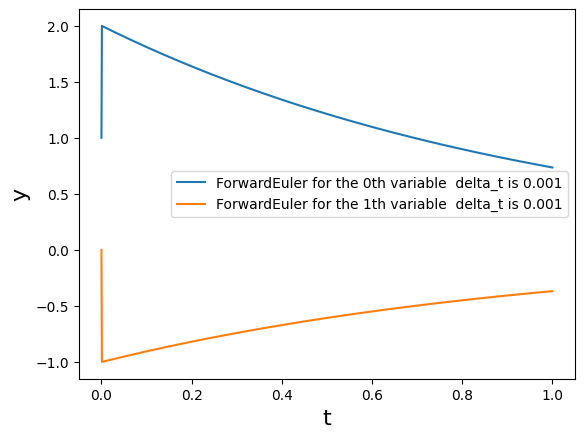

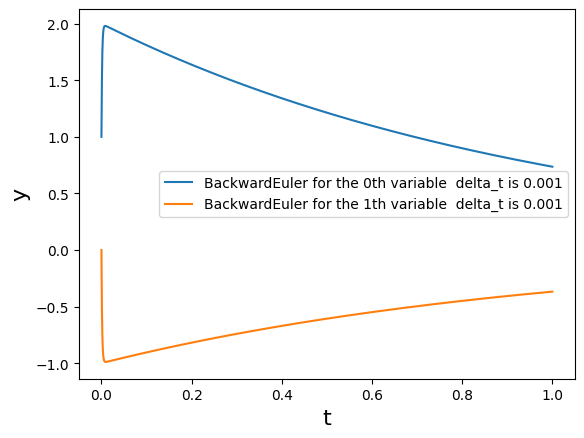

In [4]:

import numpy as np
import matplotlib.pyplot as plt

# ExplicitLinearIntegrator class

class ExplicitLinearIntegrator:

    """
    Contains explicit and implicit methods to integrate ODEs

    attributes: the matrix C_matrix, max_time,
                N_time_steps, method

    methods: calculate_solution, plot_solution
    """

    integration_methods = ["ForwardEuler", "BackwardEuler"]

    # constructor function
    def __init__(self, a_C_matrix, max_time=0,
                 N_time_steps=0, method="ForwardEuler"):

        self.C_matrix = a_C_matrix
        self.method = method

        assert self.method in self.integration_methods, \
            'chosen integration method not implemented'
        assert np.ndim(self.C_matrix) == 2, \
            'C_matrix must be a 2D matrix'
        assert np.shape(self.C_matrix)[0] == np.shape(self.C_matrix)[1], \
            'C_matrix must be square'
        assert max_time > 0, 'max_time must be positive'
        assert N_time_steps > 0, 'N_time_steps must be positive'

        # Make these private
        self._dimension = np.size(self.C_matrix, 0)
        self._max_time = max_time
        self._N_time_steps = N_time_steps

        # Derived from the values above
        self._delta_t = self.max_time / self.N_time_steps
        self._t_solution = np.linspace(
            0.0, self.max_time, self.N_time_steps + 1
        )
        self._y_solution = np.zeros(
            [self.N_time_steps + 1, self._dimension]
        )

    # Enables the user to get the y solution
    @property
    def y_solution(self):
        return self._y_solution

    # Enables the user to get the t solution
    @property
    def t_solution(self):
        return self._t_solution

    @property
    def max_time(self):
        return self._max_time

    @property
    def N_time_steps(self):
        return self._N_time_steps

    # Enables the user to reset the max time
    @max_time.setter
    def max_time(self, value):
        assert value > 0, 'max_time must be positive'
        self._max_time = value
        self._delta_t = self.max_time / self.N_time_steps
        self._t_solution = np.linspace(
            0.0, self.max_time, self.N_time_steps + 1
        )
        self._y_solution = np.zeros(
            [self.N_time_steps + 1, self._dimension]
        )

    # Enables the user to reset the number of time steps
    @N_time_steps.setter
    def N_time_steps(self, value):
        assert isinstance(value, (int, np.integer)) and value > 0, \
            'N_time_steps must be a positive integer'
        self._N_time_steps = value
        self._delta_t = self.max_time / self.N_time_steps
        self._t_solution = np.linspace(
            0.0, self.max_time, self.N_time_steps + 1
        )
        self._y_solution = np.zeros(
            [self.N_time_steps + 1, self._dimension]
        )

    def calculate_solution(self, y0):

        assert len(y0) == self._dimension, \
            'Initial condition dimension does not match C_matrix'

        if self.method == "ForwardEuler":
            self.integrate_using_forward_Euler(y0)

        elif self.method == "BackwardEuler":
            self.integrate_using_backward_Euler(y0)

        else:
            assert False, 'integration method not implemented'

        assert np.all(np.isfinite(self._y_solution)), \
            'Solution contains non-finite values'

    def plot_solution(self):

        plt.xlabel("t", fontsize=16)
        plt.ylabel("y", fontsize=16)

        for i in np.arange(self._dimension):
            plt.plot(
                self._t_solution,
                self._y_solution[:, i],
                '-',
                label=self.method + " for the " + str(i) +
                "th variable " +
                " delta_t is " + str(self._delta_t)
            )

        plt.legend()
        plt.show()

    def integrate_using_forward_Euler(self, y0):

        h = self._delta_t
        I_matrix = np.eye(self._dimension)

        # Forward Euler: y_new = (I - hC) y_old
        I_minus_hC = I_matrix - h * self.C_matrix

        for itime, time in enumerate(self.t_solution):
            if itime == 0:
                self._y_solution[itime, :] = y0
            else:
                yold = self._y_solution[itime - 1, :]
                ynew = I_minus_hC @ yold
                self._y_solution[itime, :] = ynew

        # Sanity checks
        assert np.allclose(self._y_solution[0, :], y0)
        assert np.all(np.isfinite(self._y_solution))

    # Backward Euler method
    def integrate_using_backward_Euler(self, y0):

        h = self._delta_t
        I_matrix = np.eye(self._dimension)

        # Backward Euler: (I + hC) y_new = y_old
        I_plus_hC = I_matrix + h * self.C_matrix

        for itime, time in enumerate(self.t_solution):
            if itime == 0:
                self._y_solution[itime, :] = y0
            else:
                yold = self._y_solution[itime - 1, :]

                # Solve the implicit equation
                ynew = np.linalg.solve(I_plus_hC, yold)

                self._y_solution[itime, :] = ynew

        # Sanity checks
        assert np.allclose(self._y_solution[0, :], y0)
        assert np.all(np.isfinite(self._y_solution))


# How to use the class - example from the lecture

C_matrix = np.matrix([
    [-998, -1998],
    [999, 1999]
])

y0 = np.array([1.0, 0.0])
max_time = 1.0
N_time_steps = 1000

# Define an object of the class
stiff_problem_integrator = ExplicitLinearIntegrator(
    C_matrix,
    max_time,
    N_time_steps,
    "ForwardEuler"
)

# Find and plot the solution
stiff_problem_integrator.calculate_solution(y0)
stiff_problem_integrator.plot_solution()


# Run Backward Euler
stiff_problem_integrator = ExplicitLinearIntegrator(
    C_matrix,
    max_time,
    N_time_steps,
    "BackwardEuler"
)

stiff_problem_integrator.calculate_solution(y0)
stiff_problem_integrator.plot_solution()


### ACTIVITY 2:
    
Now apply the integrator to the following coupled, second order harmonic oscillator system.

_HINT_ You first need to think carefully about what dimension this needs to be, and how to cast it into first order matrix form:

${\begin{aligned}
m_1{\ddot {x}}_{1}&=-kx_{1}+k(x_{2}-x_{1})=-2kx_{1}+kx_{2}
\\
m_2{\ddot {x}}_{2}&=-kx_{2}+k(x_{1}-x_{2})=-2kx_{2}+kx_{1}
\end{aligned}}$

where $k$ is the spring constant and $m_1$ and $m_2$ are the mass of the oscillators. Set the initial conditions as

$x_1 = 1 \quad \dot{x}_1 = 0$

$x_2 = 0 \quad \dot{x}_2 = 2$

Set $k=1$ and $m_1 = 1$ and $m_2 = 1$

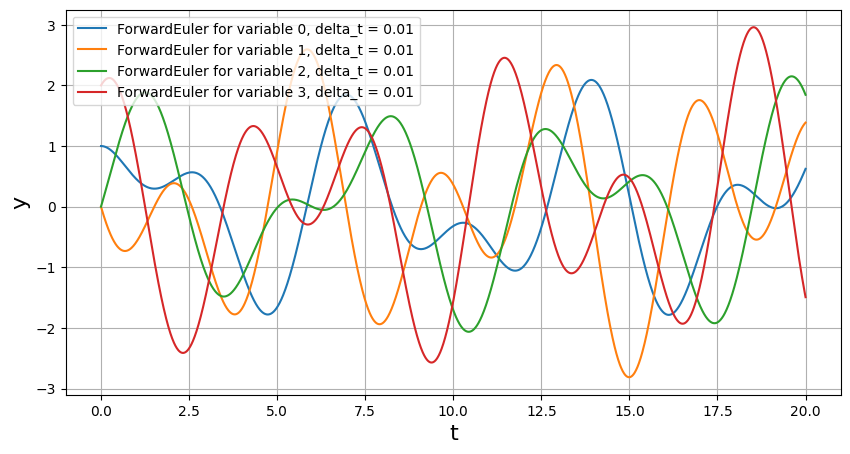

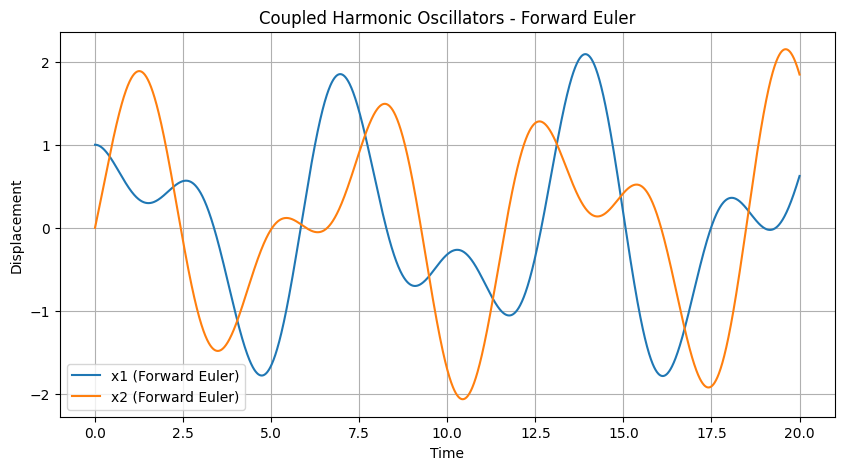

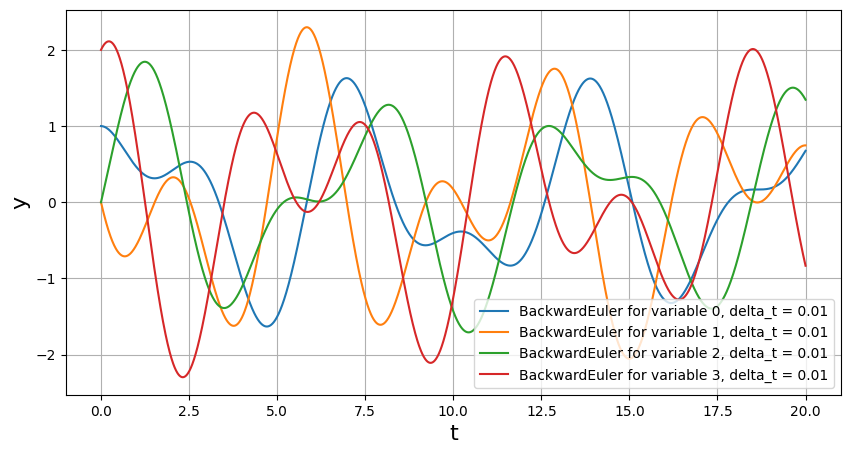

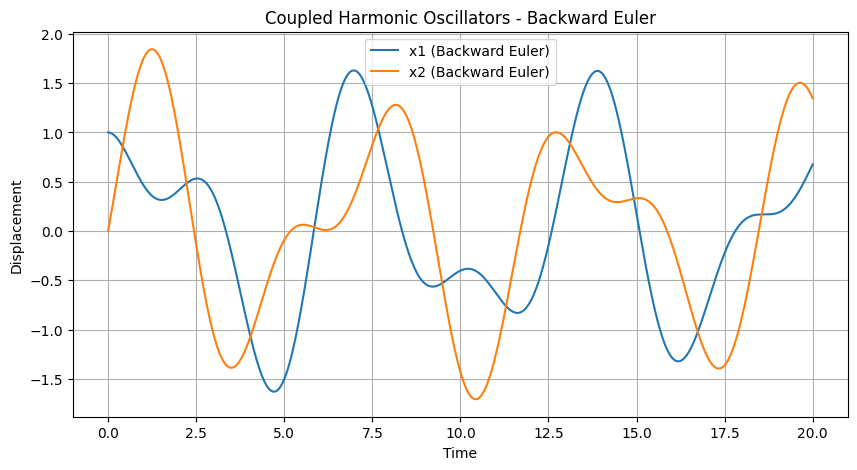

In [5]:
# Integrator for the coupled harmonic oscillator


import numpy as np
import matplotlib.pyplot as plt


# ExplicitLinearIntegrator class

class ExplicitLinearIntegrator:

    """
    Contains explicit and implicit methods to integrate ODEs

    attributes: the matrix C_matrix, max_time,
                N_time_steps, method

    methods: calculate_solution, plot_solution
    """

    integration_methods = ["ForwardEuler", "BackwardEuler"]

    # Constructor function
    def __init__(self, a_C_matrix, max_time=0,
                 N_time_steps=0, method="ForwardEuler"):

        self.C_matrix = a_C_matrix
        self.method = method

        assert self.method in self.integration_methods, \
            'chosen integration method not implemented'
        assert np.ndim(self.C_matrix) == 2, \
            'C_matrix must be a 2D matrix'
        assert np.shape(self.C_matrix)[0] == np.shape(self.C_matrix)[1], \
            'C_matrix must be square'
        assert max_time > 0, 'max_time must be positive'
        assert N_time_steps > 0, 'N_time_steps must be positive'

        # Make these private
        self._dimension = np.size(self.C_matrix, 0)
        self._max_time = max_time
        self._N_time_steps = N_time_steps

        # Derived from the values above
        self._delta_t = self.max_time / self.N_time_steps
        self._t_solution = np.linspace(
            0.0, self.max_time, self.N_time_steps + 1
        )
        self._y_solution = np.zeros(
            [self.N_time_steps + 1, self._dimension]
        )

    # Enables the user to get the y solution
    @property
    def y_solution(self):
        return self._y_solution

    # Enables the user to get the t solution
    @property
    def t_solution(self):
        return self._t_solution

    @property
    def max_time(self):
        return self._max_time

    @property
    def N_time_steps(self):
        return self._N_time_steps

    # Enables the user to reset the max time
    @max_time.setter
    def max_time(self, value):
        assert value > 0, 'max_time must be positive'
        self._max_time = value
        self._delta_t = self.max_time / self.N_time_steps
        self._t_solution = np.linspace(
            0.0, self.max_time, self.N_time_steps + 1
        )
        self._y_solution = np.zeros(
            [self.N_time_steps + 1, self._dimension]
        )

    # Enables the user to reset the number of time steps
    @N_time_steps.setter
    def N_time_steps(self, value):
        assert isinstance(value, (int, np.integer)) and value > 0, \
            'N_time_steps must be a positive integer'
        self._N_time_steps = value
        self._delta_t = self.max_time / self.N_time_steps
        self._t_solution = np.linspace(
            0.0, self.max_time, self.N_time_steps + 1
        )
        self._y_solution = np.zeros(
            [self.N_time_steps + 1, self._dimension]
        )

    def calculate_solution(self, y0):

        y0 = np.asarray(y0, dtype=float)

        assert y0.shape == (self._dimension,), \
            'Initial condition dimension does not match C_matrix'

        if self.method == "ForwardEuler":
            self.integrate_using_forward_Euler(y0)

        elif self.method == "BackwardEuler":
            self.integrate_using_backward_Euler(y0)

        else:
            assert False, 'integration method not implemented'

        assert np.all(np.isfinite(self._y_solution)), \
            'Solution contains non-finite values'

    def plot_solution(self):

        plt.figure(figsize=(10, 5))
        plt.xlabel("t", fontsize=16)
        plt.ylabel("y", fontsize=16)

        for i in np.arange(self._dimension):
            plt.plot(
                self._t_solution,
                self._y_solution[:, i],
                '-',
                label=self.method + " for variable " + str(i)
                + ", delta_t = " + str(self._delta_t)
            )

        plt.legend()
        plt.grid(True)
        plt.show()

    def integrate_using_forward_Euler(self, y0):

        h = self._delta_t
        I_matrix = np.eye(self._dimension)

        # Forward Euler: y_new = (I - hC) y_old
        I_minus_hC = I_matrix - h * self.C_matrix

        self._y_solution[0, :] = y0

        for itime in range(1, self.N_time_steps + 1):
            yold = self._y_solution[itime - 1, :]
            ynew = I_minus_hC @ yold
            self._y_solution[itime, :] = ynew

        # Sanity checks
        assert np.allclose(self._y_solution[0, :], y0)
        assert np.all(np.isfinite(self._y_solution))

    def integrate_using_backward_Euler(self, y0):

        h = self._delta_t
        I_matrix = np.eye(self._dimension)

        # Backward Euler: (I + hC) y_new = y_old
        I_plus_hC = I_matrix + h * self.C_matrix

        self._y_solution[0, :] = y0

        for itime in range(1, self.N_time_steps + 1):
            yold = self._y_solution[itime - 1, :]

            # Solve the implicit equation
            ynew = np.linalg.solve(I_plus_hC, yold)

            self._y_solution[itime, :] = ynew

        # Sanity checks
        assert np.allclose(self._y_solution[0, :], y0)
        assert np.all(np.isfinite(self._y_solution))


# --------------------------------------------------
# Coupled harmonic oscillator system
# --------------------------------------------------

# Parameters
k = 1
m1 = 1
m2 = 1

# First-order variables:
# y[0] = x1
# y[1] = dx1/dt
# y[2] = x2
# y[3] = dx2/dt

# The integrator uses dy/dt = -C_matrix @ y
C_matrix = np.array([
    [0,        -1,       0,        0],
    [2*k/m1,    0,      -k/m1,     0],
    [0,         0,       0,       -1],
    [-k/m2,     0,       2*k/m2,   0]
], dtype=float)

# Initial conditions:
# x1(0) = 1, dx1/dt(0) = 0
# x2(0) = 0, dx2/dt(0) = 2

y0 = np.array([1.0, 0.0, 0.0, 2.0])

# Integration parameters
max_time = 20.0
N_time_steps = 2000

# --------------------------------------------------
# Forward Euler
# --------------------------------------------------

forward_integrator = ExplicitLinearIntegrator(
    C_matrix, max_time, N_time_steps, "ForwardEuler"
)

forward_integrator.calculate_solution(y0)
forward_integrator.plot_solution()

# Plot the two displacements
plt.figure(figsize=(10, 5))
plt.plot(
    forward_integrator.t_solution,
    forward_integrator.y_solution[:, 0],
    label="x1 (Forward Euler)"
)
plt.plot(
    forward_integrator.t_solution,
    forward_integrator.y_solution[:, 2],
    label="x2 (Forward Euler)"
)
plt.xlabel("Time")
plt.ylabel("Displacement")
plt.title("Coupled Harmonic Oscillators - Forward Euler")
plt.legend()
plt.grid(True)
plt.show()


# --------------------------------------------------
# Backward Euler
# --------------------------------------------------

backward_integrator = ExplicitLinearIntegrator(
    C_matrix, max_time, N_time_steps, "BackwardEuler"
)

backward_integrator.calculate_solution(y0)
backward_integrator.plot_solution()

# Plot the two displacements
plt.figure(figsize=(10, 5))
plt.plot(
    backward_integrator.t_solution,
    backward_integrator.y_solution[:, 0],
    label="x1 (Backward Euler)"
)
plt.plot(
    backward_integrator.t_solution,
    backward_integrator.y_solution[:, 2],
    label="x2 (Backward Euler)"
)
plt.xlabel("Time")
plt.ylabel("Displacement")
plt.title("Coupled Harmonic Oscillators - Backward Euler")
plt.legend()
plt.grid(True)
plt.show()


### ACTIVITY 3

Now we will try solving the systems with sympy. Below is the code for the lecture example. Update it to solve for the coupled harmonic oscillator above, checking against your numerical solution. Is that equation stiff or not? How can you tell?

In [ ]:
# Solution of coupled linear equations using sympy

import sympy as sp
from sympy import symbols, Eq, Function, pprint, Matrix
from sympy.solvers.ode.systems import dsolve_system

# Compare the eigenvalue decomposition
C_matrix =  Matrix([[998, 1998],[-999, -1999]])
C_inverse = C_matrix.inv()
eigenvalues_and_vectors = C_matrix.eigenvects()

print("\n The matrix is ")
pprint(C_matrix)
print("\n Its inverse is ")
pprint(C_inverse)
print("\n Eigenvalues and eigenvectors are ")
pprint(eigenvalues_and_vectors)

# solve the linear system of ODEs
x = Function("x")
y = Function("y")
t = symbols("t")

my_equations = [Eq(x(t).diff(t), 998*x(t) + 1998*y(t)),
                Eq(y(t).diff(t), -999*x(t) - 1999*y(t))]

solution = dsolve_system(my_equations)
print("\n General solution is")
pprint(solution[0][0])
pprint(solution[0][1])

solution_with_ics = dsolve_system(my_equations, ics={x(0): 1, y(0): 0})
print("\n Specific solution with initial conditions is")
pprint(solution_with_ics[0][0])
pprint(solution_with_ics[0][1])


 The matrix is 
⎡998   1998 ⎤
⎢           ⎥
⎣-999  -1999⎦

 Its inverse is 
⎡-1999   -999 ⎤
⎢──────  ─────⎥
⎢ 1000    500 ⎥
⎢             ⎥
⎢ 999     499 ⎥
⎢ ────    ─── ⎥
⎣ 1000    500 ⎦

 Eigenvalues and eigenvectors are 
⎡⎛          ⎡⎡-1⎤⎤⎞  ⎛       ⎡⎡-2⎤⎤⎞⎤
⎢⎜-1000, 1, ⎢⎢  ⎥⎥⎟, ⎜-1, 1, ⎢⎢  ⎥⎥⎟⎥
⎣⎝          ⎣⎣1 ⎦⎦⎠  ⎝       ⎣⎣1 ⎦⎦⎠⎦

 General solution is
             -1000⋅t         -t
x(t) = - C₁⋅ℯ        - 2⋅C₂⋅ℯ  
           -1000⋅t       -t
y(t) = C₁⋅ℯ        + C₂⋅ℯ  

 Specific solution with initial conditions is
          -t    -1000⋅t
x(t) = 2⋅ℯ   - ℯ       
          -t    -1000⋅t
y(t) = - ℯ   + ℯ       


In [6]:

import sympy as sp
from sympy import symbols, Eq, Function, pprint, Matrix
from sympy.solvers.ode.systems import dsolve_system

# Parameters
k = 1
m1 = 1
m2 = 1

t = symbols("t", real=True)

# First-order system matrix
A_matrix = Matrix([
    [0,        1,       0,        0],
    [-2*k/m1,  0,       k/m1,     0],
    [0,        0,       0,        1],
    [k/m2,     0,      -2*k/m2,   0]
])

print("\nThe matrix is")
pprint(A_matrix)

print("\nEigenvalues and eigenvectors are")
pprint(A_matrix.eigenvects())

# Define the four functions
x1 = Function("x1")
v1 = Function("v1")
x2 = Function("x2")
v2 = Function("v2")

# Coupled second-order equations written as four first-order equations
my_equations = [
    Eq(x1(t).diff(t), v1(t)),
    Eq(v1(t).diff(t), -2*x1(t) + x2(t)),
    Eq(x2(t).diff(t), v2(t)),
    Eq(v2(t).diff(t), x1(t) - 2*x2(t))
]

# General solution
solution = dsolve_system(my_equations)

print("\nGeneral solution is")
for equation in solution[0]:
    pprint(equation)

# Solution with initial conditions
solution_with_ics = dsolve_system(
    my_equations,
    ics={
        x1(0): 1,
        v1(0): 0,
        x2(0): 0,
        v2(0): 2
    }
)

print("\nSpecific solution with initial conditions is")
for equation in solution_with_ics[0]:
    pprint(equation)



The matrix is
⎡ 0    1   0    0⎤
⎢                ⎥
⎢-2.0  0  1.0   0⎥
⎢                ⎥
⎢ 0    0   0    1⎥
⎢                ⎥
⎣1.0   0  -2.0  0⎦

Eigenvalues and eigenvectors are
⎡⎛                        ⎡⎡ 0.353553390593274  ⎤⎤⎞  ⎛           ⎡⎡0.5⋅ⅈ⎤⎤⎞  ⎛ ↪
⎢⎜                        ⎢⎢                    ⎥⎥⎟  ⎜           ⎢⎢     ⎥⎥⎟  ⎜ ↪
⎢⎜                        ⎢⎢-0.612372435695794⋅ⅈ⎥⎥⎟  ⎜           ⎢⎢ 0.5 ⎥⎥⎟  ⎜ ↪
⎢⎜-1.73205080756888⋅ⅈ, 1, ⎢⎢                    ⎥⎥⎟, ⎜-1.0⋅ⅈ, 1, ⎢⎢     ⎥⎥⎟, ⎜ ↪
⎢⎜                        ⎢⎢ -0.353553390593274 ⎥⎥⎟  ⎜           ⎢⎢0.5⋅ⅈ⎥⎥⎟  ⎜ ↪
⎢⎜                        ⎢⎢                    ⎥⎥⎟  ⎜           ⎢⎢     ⎥⎥⎟  ⎜ ↪
⎣⎝                        ⎣⎣0.612372435695794⋅ⅈ ⎦⎦⎠  ⎝           ⎣⎣ 0.5 ⎦⎦⎠  ⎝ ↪

↪           ⎡⎡0.5⋅ⅈ⎤⎤⎞  ⎛                       ⎡⎡ 0.408248290463863  ⎤⎤⎞⎤
↪           ⎢⎢     ⎥⎥⎟  ⎜                       ⎢⎢                    ⎥⎥⎟⎥
↪           ⎢⎢-0.5 ⎥⎥⎟  ⎜                       ⎢⎢0.707106781186548⋅ⅈ ⎥⎥⎟⎥
↪ 1.0⋅ⅈ, 1, ⎢⎢     ⎥⎥⎟, ⎜

### ACTIVITY 4

Which is faster, sympy or numpy?

Generate an NxN matrix containing random integers both sympy and numpy.

Compute the inverse using both libraries and calculate the time taken to do this. Repeat this for a range of N and see which one scales better - make a plot of your results. What do you conclude?

_HINT_ Recall that we talked about timing functions in the Week 1 lecture.

N = 3
NumPy time: 0.000129 seconds
SymPy time: 0.000842 seconds

N = 5
NumPy time: 0.000070 seconds
SymPy time: 0.005347 seconds

N = 10
NumPy time: 0.000104 seconds
SymPy time: 0.017382 seconds

N = 20
NumPy time: 0.000116 seconds
SymPy time: 0.055731 seconds

N = 30
NumPy time: 0.000181 seconds
SymPy time: 0.096435 seconds

N = 40
NumPy time: 0.000231 seconds
SymPy time: 0.331708 seconds



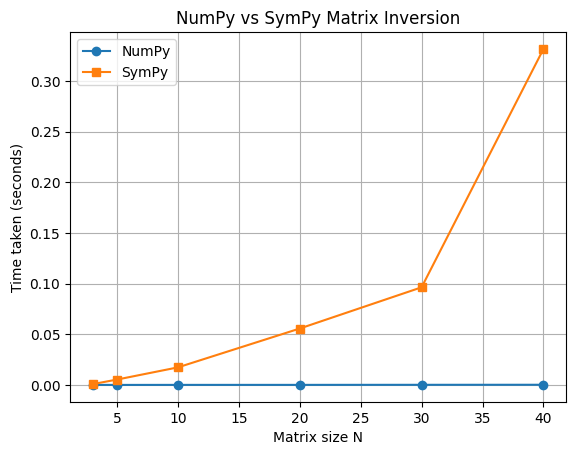

[[6 0 8]
 [2 0 2]
 [0 6 9]]
[[-0.5         2.          0.        ]
 [-0.75        2.25        0.16666667]
 [ 0.5        -1.5        -0.        ]]


In [7]:
# UPDATE ME!

import numpy as np
import sympy as sp
import time
import matplotlib.pyplot as plt

N_values = [3, 5, 10, 20, 30, 40]
numpy_times = []
sympy_times = []

for N in N_values:

    # Generate a random integer matrix
    my_matrix = np.random.randint(low=0, high=10, size=[N, N])

    # Make sure the matrix is invertible
    my_matrix = my_matrix + 10 * N * np.eye(N, dtype=int)

    # NumPy inversion and timing
    start = time.perf_counter()
    numpy_inverse = np.linalg.inv(my_matrix.astype(float))
    numpy_times.append(time.perf_counter() - start)

    # SymPy inversion and timing
    sympy_matrix = sp.Matrix(my_matrix.tolist())

    start = time.perf_counter()
    sympy_inverse = sympy_matrix.inv()
    sympy_times.append(time.perf_counter() - start)

    print(f"N = {N}")
    print(f"NumPy time: {numpy_times[-1]:.6f} seconds")
    print(f"SymPy time: {sympy_times[-1]:.6f} seconds")
    print()

# Plot the timings
plt.plot(N_values, numpy_times, 'o-', label="NumPy")
plt.plot(N_values, sympy_times, 's-', label="SymPy")

plt.xlabel("Matrix size N")
plt.ylabel("Time taken (seconds)")
plt.title("NumPy vs SymPy Matrix Inversion")
plt.legend()
plt.grid(True)
plt.show()

my_matrix = numpy.random.randint(low=0, high=10, size=[3,3])

print(my_matrix)

print(np.linalg.inv(my_matrix))